<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/50_vinculos/51_cumaribo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 51 · Cumaribo: quema previa y conversión de praderas

**Autor:** Jonatan

**Pregunta:** en Cumaribo, ¿la pradera con quema previa se convierte más o menos a uso agropecuario que la que no se quemó? (hipótesis H3, a nivel de píxel)

**Entradas:**
- `modulos/fuego_expansion/datos/crudos/` (DVC): TIFF anuales de cobertura (2000–2024) y de fuego (2000–2025) de MapBiomas para Cumaribo.
- `datos/comunes/grilla_2km.gpkg` (cuaderno 02, DVC): grilla común de celdas de 2 km.

**Salidas:**
- `modulos/fuego_expansion/resultados/tablas/cumaribo/`: `conversion_anual.csv`, `conversion_por_quema_previa.csv`, `contraste_quema_acumulado.csv`, `tasas_celdas_2km.csv` y `moran_local_2km.csv`.
- `modulos/fuego_expansion/resultados/figuras/cumaribo/`: tres figuras.
- `modulos/fuego_expansion/datos/derivados/cumaribo/primera_conversion_pradera.tif` (no se versiona).

**Método:** cruce píxel a píxel de la cobertura y el fuego, tasas de conversión según quema previa con intervalos por bootstrap y Moran local de las tasas en celdas de 2 km (corrección de Benjamini-Hochberg). Las celdas son las de la grilla común (EPSG:9377) y se identifican con `id_celda`.

## Cumaribo · Quema previa y conversión persistente de praderas

El panel de los cuadernos 23, 50 y 52 relaciona totales municipales. Aquí seguimos la cobertura de los mismos píxeles año a año para identificar dónde se convirtió la pradera y qué parte de esa superficie tenía quema previa detectada. El análisis se limita a Cumaribo. La unidad aquí es el píxel. Las tasas espaciales cuentan primeras conversiones persistentes de pradera sobre pradera elegible. Las dos medidas del cuaderno 50 dividen el saldo agropecuario municipal por el territorio previo o por el área agropecuaria previa.

## 1. Inventario y cuadrícula

Se indexan los TIFF por el año del nombre. Antes de cruzarlos se verifica que los mapas utilizados tengan idénticas dimensiones, sistema de coordenadas y transformación de píxel a coordenadas. El cruce se hace en la cuadrícula original. Las hectáreas de cada píxel se miden en una proyección de área equivalente (EPSG:6933). Cada píxel se asigna por su centro a una celda de la grilla común de 2 km, en EPSG:9377.

In [6]:
from pathlib import Path
import sys
from importlib import import_module

import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display

# Rutas del proyecto: funcionan en Colab y en local
import os, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/

def traer(ruta):
    """Baja de DVC una carpeta o un archivo pesado del repo si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

traer('modulos/fuego_expansion/datos/crudos')
traer('datos/comunes/grilla_2km.gpkg')
sys.path.insert(0, os.path.join(RAIZ, 'modulos', 'fuego_expansion', 'scripts'))
import config as cfg
from utils import estilo_matplotlib, pie_fuente

espacial = import_module("06_conversion_cumaribo")
cobertura = espacial.archivos_anuales(cfg.CRUDOS / "mapbiomas_coverage_cumaribo_tiff")
fuego = espacial.archivos_anuales(cfg.CRUDOS / "mapbiomas_fire_cumaribo_tiff")
for nombre, archivos in [("Cobertura", cobertura), ("Fuego", fuego)]:
    print(f"{nombre}: {min(archivos)}–{max(archivos)} ({len(archivos)} archivos)")

derivados = cfg.DERIVADOS / "cumaribo"
tablas = cfg.TABLAS / "cumaribo"
figuras = cfg.FIGURAS / "cumaribo"
for carpeta in (derivados, tablas, figuras):
    carpeta.mkdir(parents=True, exist_ok=True)
estilo_matplotlib()

Cobertura: 2000–2024 (25 archivos)
Fuego: 2000–2025 (26 archivos)


## 2. Primera conversión persistente

Para una conversión detectada en el año *t*, el píxel debe ser pradera o herbácea (clase 12) en *t−1* y agropecuario (9, 21 o 35) en *t*. Se exige que siga en el grupo agropecuario en *t+1*. Los píxeles con una conversión confirmada dejan de contar como pradera elegible en años posteriores. «Primera» se refiere a la primera transición persistente observada en esta serie.

Se distingue la transición de **2024**, provisional porque falta la cobertura de 2025. El GeoTIFF registra el año de la primera conversión, con 0 para píxeles válidos sin transición detectada y 65535 para píxeles fuera del área válida. La vista del notebook usa una versión reducida para mostrarla. El GeoTIFF conserva la resolución original.

Para estudiar quema previa, la función usa la detección de fuego de *t−2*, un año anterior al mapa de pradera elegible de *t−1*. Así se ubica el año completo de exposición antes del intervalo entre los mapas de *t−1* y *t*. Por ejemplo, relaciona la quema de 2021 con la transición entre coberturas de 2022 y 2023. El grupo «sin quema detectada» corresponde a píxeles sin valor de fuego positivo, dentro de la cobertura válida del año de exposición. El código de cobertura del raster de fuego queda separado de la definición de pradera elegible, que proviene del mapa de cobertura de *t−1*.

In [7]:
ruta_mapa = derivados / "primera_conversion_pradera.tif"
anual, contraste, celdas = espacial.analizar_conversiones(cobertura, fuego, ruta_mapa)
celdas, fuera = espacial.unir_grilla(celdas, cfg.COMUNES / "grilla_2km.gpkg")
pradera_fuera = fuera["pradera_ha_anio"].sum()
print(f"Celdas de la grilla común con pradera elegible: {len(celdas):,}")
print(f"Celdas fuera de la grilla: {len(fuera):,} "
      f"({pradera_fuera / (pradera_fuera + celdas['pradera_ha_anio'].sum()):.2%} de las hectáreas-año de pradera)")
anual.to_csv(tablas / "conversion_anual.csv", index=False, encoding="utf-8-sig")
contraste.to_csv(tablas / "conversion_por_quema_previa.csv", index=False, encoding="utf-8-sig")
display(anual.round(3))

Celdas de la grilla común con pradera elegible: 10,020
Celdas fuera de la grilla: 0 (0.00% de las hectáreas-año de pradera)


,anio,pradera_elegible_ha,conversion_ha,confirmada,tasa_pct
0,2001,1688140.175,5258.970,True,0.312
1,2002,1679441.288,7185.095,True,0.428
2,2003,1677895.828,5007.624,True,0.298
3,2004,1679239.726,13136.542,True,0.782
4,2005,1671671.816,6852.088,True,0.410
5,2006,1658309.956,4701.050,True,0.283
6,2007,1654728.636,4226.678,True,0.255
7,2008,1655275.361,6428.863,True,0.388
8,2009,1648802.762,5736.871,True,0.348
9,2010,1636050.149,4788.676,True,0.293


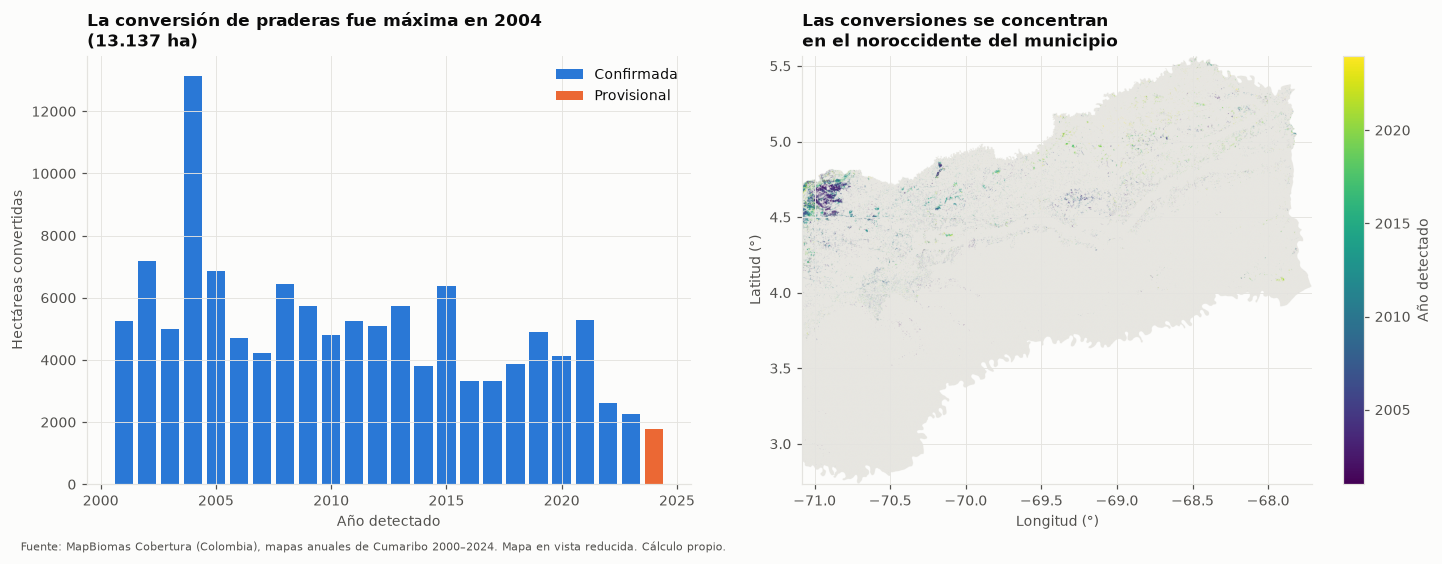

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
confirmadas = anual[anual["confirmada"]]
provisional = anual[~anual["confirmada"]]
ejes[0].bar(confirmadas["anio"], confirmadas["conversion_ha"], color=cfg.COLOR_AGRO, label="Confirmada")
ejes[0].bar(provisional["anio"], provisional["conversion_ha"], color=cfg.COLOR_SABANA, label="Provisional")
pico = confirmadas.loc[confirmadas["conversion_ha"].idxmax()]
ejes[0].set(title=f"La conversión de praderas fue máxima en {int(pico['anio'])}\n({pico['conversion_ha']:,.0f} ha)".replace(",", "."),
            xlabel="Año detectado", ylabel="Hectáreas convertidas")
ejes[0].legend()
with rasterio.open(ruta_mapa) as src:
    vista = src.read(1, out_shape=(src.height // 4, src.width // 4))
    oeste, sur, este, norte = src.bounds
fondo = np.where(vista == espacial.NODATA_SALIDA, np.nan, 1)
ejes[1].imshow(fondo, extent=(oeste, este, sur, norte), cmap=ListedColormap(["#e7e6e1"]))
cambio = np.ma.masked_where((vista == 0) | (vista == espacial.NODATA_SALIDA), vista)
mapa = ejes[1].imshow(cambio, extent=(oeste, este, sur, norte), cmap="viridis",
                      vmin=anual["anio"].min(), vmax=anual["anio"].max())
ejes[1].set(title="Las conversiones se concentran\nen el noroccidente del municipio", xlabel="Longitud (°)", ylabel="Latitud (°)")
fig.colorbar(mapa, ax=ejes[1], label="Año detectado")
fig.get_layout_engine().set(rect=(0, 0.04, 1, 0.96))
pie_fuente(fig, "Fuente: MapBiomas Cobertura (Colombia), mapas anuales de Cumaribo 2000–2024. Mapa en vista reducida. Cálculo propio.")
fig.savefig(figuras / "conversion_anual_y_mapa.png")
plt.show()

### Lectura de la serie y el mapa

Entre 2001 y 2023 se identificaron **119.295 ha** con una primera conversión persistente. **2004** tuvo el mayor registro, **13.137 ha**. El mapa muestra una concentración visible hacia el extremo noroccidental y conversiones más dispersas en otras partes del municipio. Las **1.786 ha** detectadas en 2024 se reportan por separado porque aún no se puede aplicar el criterio de persistencia. Las hectáreas corresponden a primeras conversiones observadas desde pradera. El cambio neto agropecuario del panel municipal incluye otras entradas y salidas de cobertura.

## 3. Comparar las tasas según quema previa

Cada tasa divide la superficie convertida por la pradera elegible de su propio grupo y año. La comparación utiliza conversiones confirmadas. En las tasas acumuladas del período se suman primero las hectáreas del numerador y del denominador. Por tanto, los años con mayor superficie elegible tienen más peso.

El segundo cálculo excluye exposiciones al fuego de 2002, 2005 y 2007, cuando MapBiomas complementó Landsat con MODIS MCD64A1. El contraste es descriptivo. La ubicación de la quema y la conversión puede coincidir con diferencias de accesibilidad, uso del suelo u otras características. [Nota de calidad de MapBiomas Fuego](https://colombia.mapbiomas.org/iniciativas-y-productos/fuego/calidad-mosaico/)

pradera_elegible_ha  \
muestra                               grupo                                      
Completa                              Con quema detectada         7.475837e+06   
                                      Sin quema detectada         2.855137e+07   
Sin exposiciones de 2002, 2005 y 2007 Con quema detectada         6.579521e+06   
                                      Sin quema detectada         2.446491e+07   

                                                           conversion_ha  \
muestra                               grupo                                
Completa                              Con quema detectada     11491.5418   
                                      Sin quema detectada    102544.3407   
Sin exposiciones de 2002, 2005 y 2007 Con quema detectada      8667.7924   
                                      Sin quema detectada     82267.9991   

                                                           tasa_pct  
muestra                               grupo                          
Completa                              Con quema detectada    0.1537  
                                      Sin quema detectada    0.3592  
Sin exposiciones de 2002, 2005 y 2007 Con quema detectada    0.1317  
                                      Sin quema detectada    0.3363

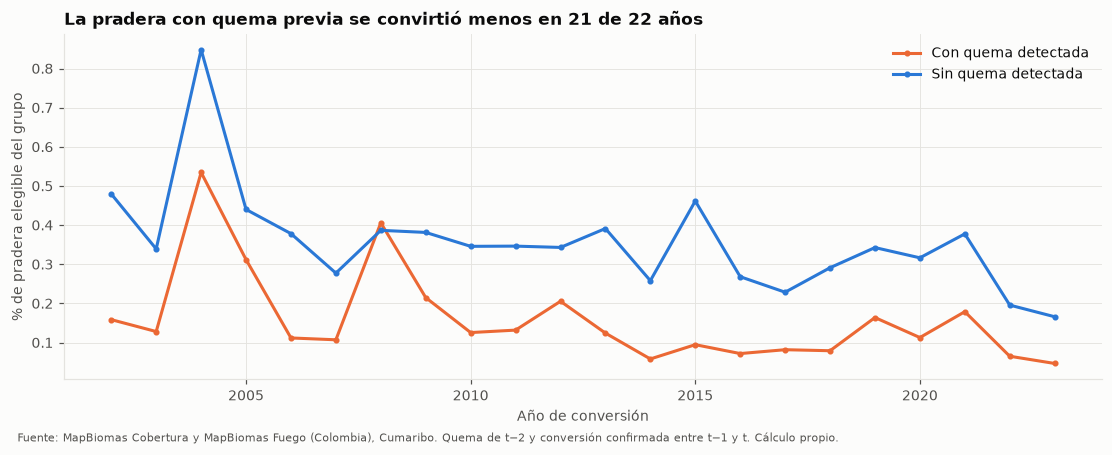

In [9]:
comparable = contraste[contraste["confirmada"]]
muestras = {
    "Completa": comparable,
    "Sin exposiciones de 2002, 2005 y 2007": comparable[
        ~comparable["anio_fuego"].isin(cfg.ANIOS_FUEGO_LIMITADOS)
    ],
}
acumulado = pd.concat({
    nombre: datos.groupby("grupo")[["pradera_elegible_ha", "conversion_ha"]].sum()
    for nombre, datos in muestras.items()
}, names=["muestra"])
acumulado["tasa_pct"] = 100 * acumulado["conversion_ha"] / acumulado["pradera_elegible_ha"]
acumulado.to_csv(tablas / "contraste_quema_acumulado.csv", encoding="utf-8-sig")
display(acumulado.round(4))

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for (grupo, serie), color in zip(comparable.groupby("grupo"), (cfg.COLOR_SABANA, cfg.COLOR_AGRO)):
    ax.plot(serie["anio"], serie["tasa_pct"], "o-", markersize=3, label=grupo, color=color)
por_anio = comparable.pivot(index="anio", columns="grupo", values="tasa_pct")
menor = int((por_anio["Con quema detectada"] < por_anio["Sin quema detectada"]).sum())
ax.set(title=f"La pradera con quema previa se convirtió menos en {menor} de {len(por_anio)} años",
       xlabel="Año de conversión", ylabel="% de pradera elegible del grupo")
ax.legend()
fig.get_layout_engine().set(rect=(0, 0.04, 1, 0.96))
pie_fuente(fig, "Fuente: MapBiomas Cobertura y MapBiomas Fuego (Colombia), Cumaribo. Quema de t−2 y conversión confirmada entre t−1 y t. Cálculo propio.")
fig.savefig(figuras / "tasas_segun_quema_previa.png")
plt.show()

### Lectura del contraste

En **21 de 22 años** con exposición previa y conversión confirmada, la tasa fue menor en el grupo con quema detectada. Al sumar los numeradores y denominadores del período, se convirtió el **0,154 %** de la pradera elegible con quema detectada frente al **0,359 %** del grupo sin detección en ese año de exposición. Al excluir las exposiciones con limitaciones de Landsat, las tasas son **0,132 %** y **0,336 %**. La diferencia es descriptiva. Puede reflejar que las zonas quemadas y las zonas donde se expande el agro se ubican en lugares distintos.

## 4. Detectar agrupamientos de conversiones con Moran local

Se asignan los píxeles por su centro a las celdas de la grilla común de 2 km (`id_celda`, EPSG:9377). Las tablas llevan el municipio de cada celda como código DIVIPOLA de 5 dígitos; las celdas del límite pueden pertenecer a un municipio vecino. La tasa de cada celda expresa **hectáreas convertidas por cada 1.000 hectáreas-año de pradera elegible**, acumuladas entre 2001 y 2023. Una hectárea disponible durante diez años aporta diez hectáreas-año al denominador. Se excluyen celdas con menos de **100 hectáreas-año** y celdas sin vecinos elegibles para reducir la influencia de denominadores muy pequeños y poder calcular el indicador.

Se usa vecindad reina, que incluye celdas adyacentes por borde o esquina, con igual peso entre los vecinos de cada celda. Moran local compara la tasa de una celda con la de sus vecinas. **Alto–alto** y **bajo–bajo** indican agrupamientos de tasas similares por encima o por debajo de la media de las celdas analizadas. Los otros dos cuadrantes muestran contrastes locales. Los valores *p* bilaterales usan 9.999 permutaciones condicionales y se ajustan con Benjamini–Hochberg. El mapa destaca celdas con *q* < 0,05. Los patrones dependen de la escala, la vecindad y el umbral elegidos. [Moran local](https://doi.org/10.1111/j.1538-4632.1995.tb00338.x)

,celdas
grupo_moran,
Sin señal al 5 %,8421
Alto–alto,128
Bajo–alto,4


Moran global descriptivo: 0.581
Celdas con pradera elegible: 10,020 | incluidas en Moran: 8,553


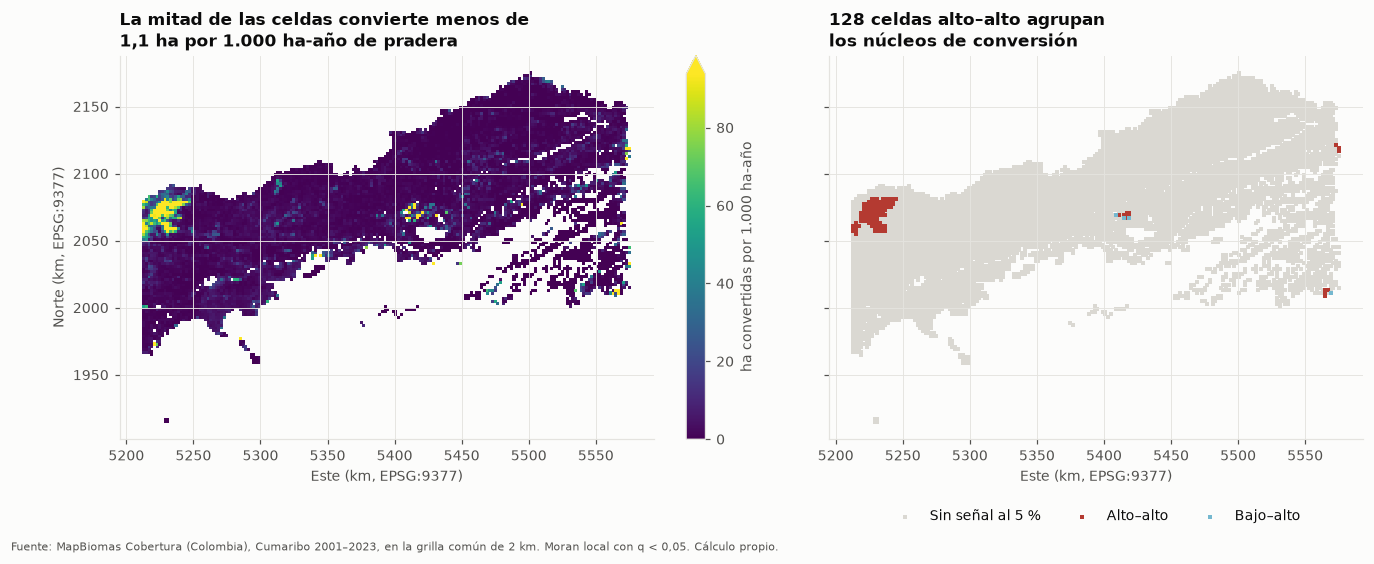

In [10]:
moran = espacial.moran_local(celdas, permutaciones=9999)
celdas.to_csv(tablas / "tasas_celdas_2km.csv", index=False, encoding="utf-8-sig")
moran.to_csv(tablas / "moran_local_2km.csv", index=False, encoding="utf-8-sig")
display(moran["grupo_moran"].value_counts().rename("celdas").to_frame())
print(f"Moran global descriptivo: {moran['moran_local'].mean():.3f}")
print(f"Celdas con pradera elegible: {len(celdas):,} | incluidas en Moran: {len(moran):,}")

fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True, layout="constrained")
puntos = ejes[0].scatter(moran["x_m"] / 1000, moran["y_m"] / 1000,
                        c=moran["conversion_por_1000_ha_anio"], s=4, marker="s", linewidths=0,
                        cmap="viridis", vmax=moran["conversion_por_1000_ha_anio"].quantile(0.99))
fig.colorbar(puntos, ax=ejes[0], label="ha convertidas por 1.000 ha-año", extend="max")
colores = {"Sin señal al 5 %": "#dad8d2", "Alto–alto": "#b43a31", "Bajo–bajo": "#2869a6",
           "Alto–bajo": "#e39849", "Bajo–alto": "#75b8cf", "Sin cuadrante": "#777777"}
for grupo, color in colores.items():
    d = moran[moran["grupo_moran"] == grupo]
    if not d.empty:
        ejes[1].scatter(d["x_m"] / 1000, d["y_m"] / 1000, c=color, s=4,
                        marker="s", linewidths=0, label=grupo)
mediana = f"{moran['conversion_por_1000_ha_anio'].median():.1f}".replace(".", ",")
ejes[0].set(title=f"La mitad de las celdas convierte menos de\n{mediana} ha por 1.000 ha-año de pradera",
            ylabel="Norte (km, EPSG:9377)")
ejes[1].set(title=f"{int((moran['grupo_moran'] == 'Alto–alto').sum())} celdas alto–alto agrupan\nlos núcleos de conversión")
for ax in ejes:
    ax.set(xlabel="Este (km, EPSG:9377)", aspect="equal")
ejes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=3)
fig.get_layout_engine().set(rect=(0, 0.04, 1, 0.96))
pie_fuente(fig, "Fuente: MapBiomas Cobertura (Colombia), Cumaribo 2001–2023, en la grilla común de 2 km. Moran local con q < 0,05. Cálculo propio.")
fig.savefig(figuras / "moran_local_conversion.png")
plt.show()

### Lectura de Moran

De **10.020 celdas** de la grilla común con alguna pradera elegible, **8.553** entraron al análisis de vecindad. El Moran global descriptivo fue **0,581**, consistente con tasas similares entre celdas vecinas. Tras el ajuste por comparaciones múltiples, **128 celdas** quedaron como alto–alto y **4** como bajo–alto. Las primeras identifican núcleos de conversión persistente de praderas. El patrón se refiere a las conversiones de 2001–2023, mientras que el mapa de cobertura de 2024 muestra la superficie agropecuaria existente en ese año.